<a href="https://colab.research.google.com/github/ShashankSatishkumar/Lasers/blob/main/4mirrorsetuppso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- PSO Optimization Results ---
Optimal d_top  : 186.98 mm
Optimal d_diag : 399.60 mm
Optimal d_bot  : 297.44 mm
Achieved Tangential Waist (w_t) : 30.00 um
Achieved Sagittal Waist   (w_s) : 30.00 um


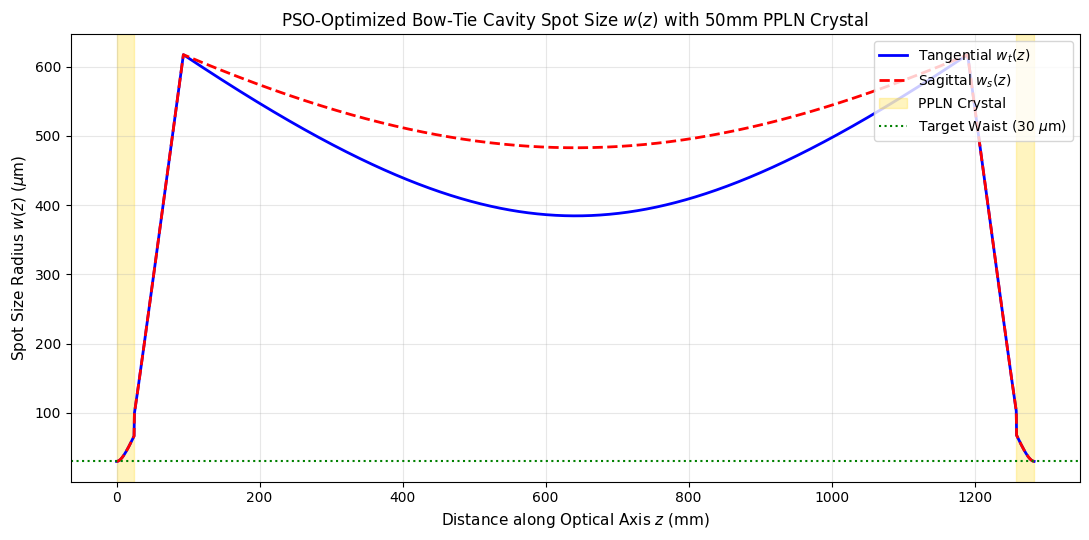

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
wavelength = 1064e-9
wavelength_mm = wavelength * 1e3

# PPLN
L_crystal = 50.0
#MgO doped ppln
n_ppln = 2.156

R = 150.0
theta_deg = 10.0
theta = np.radians(theta_deg)
 # Tangential plane
f_t = (R * np.cos(theta)) / 2.0
# Sagittal plane
f_s = (R / np.cos(theta)) / 2.0

# Beam waist
w0_target_um = 30.0  # um


def M_space(d):
    return np.array([[1.0, d], [0.0, 1.0]])

def M_dielectric(L, n):
    return np.array([[1.0, L / n], [0.0, 1.0]])

def M_mirror(f):
    return np.array([[1.0, 0.0], [-1.0 / f, 1.0]])

def get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff):
    d_air_top_half = (d_top - L_crystal) / 2.0
    if d_air_top_half <= 0:
        return None

    M_half_top_fwd = M_space(d_air_top_half) @ M_dielectric(L_crystal / 2.0, n_ppln)
    M_half_top_bwd = M_dielectric(L_crystal / 2.0, n_ppln) @ M_space(d_air_top_half)

    # Round-trip: Waist:M1:M_diag1:M_bot:M_diag2:M2:Waist
    M_rt = (
        M_half_top_bwd
        @ M_mirror(f_eff)
        @ M_space(d_diag)
        @ M_space(d_bot)
        @ M_space(d_diag)
        @ M_mirror(f_eff)
        @ M_half_top_fwd
    )
    return M_rt

def get_waist_um(M):
    if M is None:
        return None
    a, b, c, d = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
    m1 = (a + d) / 2.0
    if abs(m1) >= 1.0 or abs(b) < 1e-9:
        return None  # Unstable cavity

    inv_q_imag = np.sqrt(1.0 - m1**2) / np.abs(b)
    # Spot size inside dielectric: w0 = sqrt(lambda / (pi * n * Im(1/q)))
    w0_mm = np.sqrt(wavelength_mm / (np.pi * n_ppln * inv_q_imag))
    return w0_mm * 1e3  # convert to um
def objective_function(x):
    d_top, d_diag, d_bot = x

    if d_top <= L_crystal + 10.0 or d_diag <= 50.0 or d_bot <= 50.0:
        return 1e6

    M_t = get_roundtrip_matrix(d_top, d_diag, d_bot, f_t)
    M_s = get_roundtrip_matrix(d_top, d_diag, d_bot, f_s)

    w_t = get_waist_um(M_t)
    w_s = get_waist_um(M_s)

    if w_t is None or w_s is None:
        return 1e6
    cost = (w_t - w0_target_um) ** 2 + (w_s - w0_target_um) ** 2
    return cost

class ParticleSwarmOptimizer:
    def __init__(self, obj_func, bounds, num_particles=50, max_iter=100):
        self.obj_func = obj_func
        self.bounds = np.array(bounds)
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.dim = len(bounds)
        #initializing positions and velocities
        self.X = np.random.uniform(self.bounds[:, 0], self.bounds[:, 1], (num_particles, self.dim))
        self.V = np.random.uniform(-5, 5, (num_particles, self.dim))
        self.pbest_X = self.X.copy()
        self.pbest_cost = np.array([obj_func(x) for x in self.X])

        gbest_idx = np.argmin(self.pbest_cost)
        self.gbest_X = self.pbest_X[gbest_idx].copy()
        self.gbest_cost = self.pbest_cost[gbest_idx]

    def optimize(self, w=0.7, c1=1.5, c2=1.5):
        for _ in range(self.max_iter):
            for i in range(self.num_particles):
                r1, r2 = np.random.rand(2)
                self.V[i] = (
                    w * self.V[i]
                    + c1 * r1 * (self.pbest_X[i] - self.X[i])
                    + c2 * r2 * (self.gbest_X[i] - self.X[i])
                )
                self.X[i] += self.V[i]
                self.X[i] = np.clip(self.X[i], self.bounds[:, 0], self.bounds[:, 1])

                cost = self.obj_func(self.X[i])
                if cost < self.pbest_cost[i]:
                    self.pbest_cost[i] = cost
                    self.pbest_X[i] = self.X[i].copy()
                    if cost < self.gbest_cost:
                        self.gbest_cost = cost
                        self.gbest_X = self.X[i].copy()
        return self.gbest_X, self.gbest_cost

# Search space bounds for [d_top, d_diag, d_bot] in mm
bounds = [(70.0, 220.0), (100.0, 400.0), (100.0, 300.0)]
np.random.seed(42)
pso = ParticleSwarmOptimizer(objective_function, bounds, num_particles=60, max_iter=150)
opt_lengths, opt_cost = pso.optimize()

d_top_opt, d_diag_opt, d_bot_opt = opt_lengths
w_t_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_t))
w_s_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_s))

print(f"--- PSO Optimization Results ---")
print(f"Optimal d_top  : {d_top_opt:.2f} mm")
print(f"Optimal d_diag : {d_diag_opt:.2f} mm")
print(f"Optimal d_bot  : {d_bot_opt:.2f} mm")
print(f"Achieved Tangential Waist (w_t) : {w_t_opt:.2f} um")
print(f"Achieved Sagittal Waist   (w_s) : {w_s_opt:.2f} um")

def trace_spot_size(d_top, d_diag, d_bot, f_eff):
    M_rt = get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff)
    w0_um = get_waist_um(M_rt)
    if w0_um is None:
        return None, None

    # Solving initial complex parameter q at central waist inside PPLN
    z_R = (np.pi * n_ppln * (w0_um * 1e-3)**2) / wavelength_mm
    q = 1j * z_R  # at waist z=0 inside dielectric

    z_list, w_list = [], []
    current_z, dz = 0.0, 0.5

    d_air_top_half = (d_top - L_crystal) / 2.0
    path_sequence = [
        (L_crystal / 2.0, True),     # Half PPLN crystal
        (d_air_top_half, False),     # Air gap to mirror M2
        (0.0, False, f_eff),         # Concave Mirror M2
        (d_diag, False),             # Diagonal arm to flat mirror P1
        (d_bot, False),              # Bottom arm to flat mirror P2
        (d_diag, False),             # Diagonal arm to concave mirror M1
        (0.0, False, f_eff),         # Concave Mirror M1
        (d_air_top_half, False),     # Air gap back to PPLN
        (L_crystal / 2.0, True)      # Half PPLN crystal back to waist
    ]

    for item in path_sequence:
        dist = item[0]
        is_in_ppln = item[1]

        if len(item) == 3:  # Mirror reflection
            f_m = item[2]
            q = 1.0 / (1.0 / q - 1.0 / f_m)
        elif dist > 0:
            steps = int(np.ceil(dist / dz))
            step_d = dist / steps
            n_curr = n_ppln if is_in_ppln else 1.0

            for _ in range(steps):
                z_list.append(current_z)
                inv_q = 1.0 / q
                w_mm = np.sqrt(wavelength_mm / (np.pi * n_curr * np.abs(np.imag(inv_q))))
                w_list.append(w_mm * 1e3)
                q += step_d / n_curr
                current_z += step_d

    return np.array(z_list), np.array(w_list)

z_t, w_t = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_t)
z_s, w_s = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_s)

plt.figure(figsize=(11, 5.5))
plt.plot(z_t, w_t, 'b-', label=r'Tangential $w_t(z)$', lw=2)
plt.plot(z_s, w_s, 'r--', label=r'Sagittal $w_s(z)$', lw=2)

plt.axvspan(0, L_crystal / 2.0, color='gold', alpha=0.25, label='PPLN Crystal')
plt.axvspan(z_t[-1] - L_crystal / 2.0, z_t[-1], color='gold', alpha=0.25)

plt.axhline(w0_target_um, color='green', linestyle=':', label=r'Target Waist ($30\ \mu\mathrm{m}$)')

plt.title(r'PSO-Optimized Bow-Tie Cavity Spot Size $w(z)$ with $50\mathrm{mm}$ PPLN Crystal', fontsize=12)
plt.xlabel(r'Distance along Optical Axis $z$ (mm)', fontsize=11)
plt.ylabel(r'Spot Size Radius $w(z)$ ($\mu$m)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

--- PSO Optimization Results ---
Optimal d_top  : 204.04 mm
Optimal d_diag : 100.00 mm
Optimal d_bot  : 160.62 mm
Achieved Tangential Waist (w_t) : 78.48 um
Achieved Sagittal Waist   (w_s) : 78.48 um


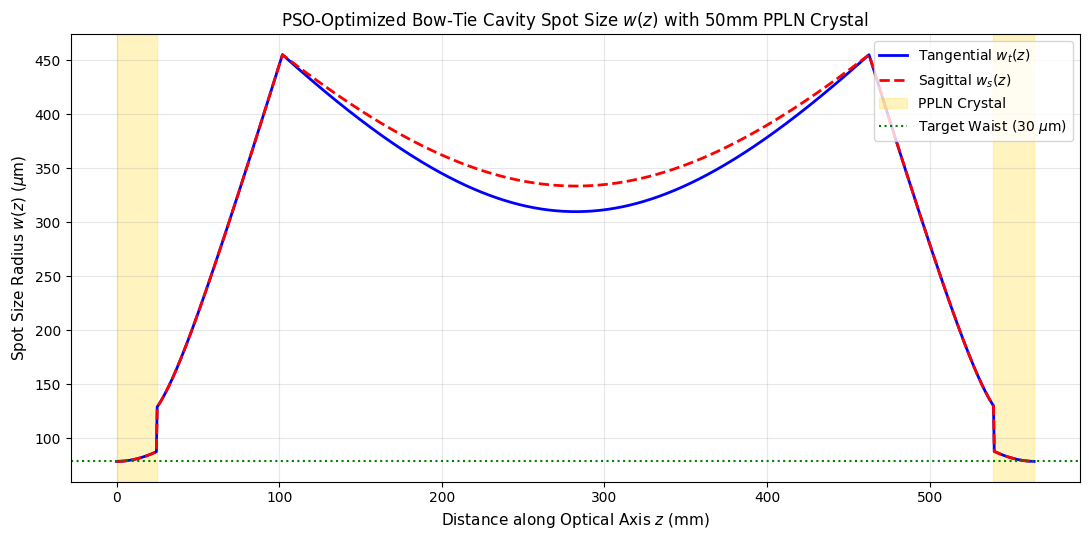

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
wavelength = 1800e-9
wavelength_mm = wavelength * 1e3

# PPLN
L_crystal = 50.0
#MgO doped ppln
n_ppln = 2.1582

R = 150.0
theta_deg = 10.0
theta = np.radians(theta_deg)
 # Tangential plane
f_t = (R * np.cos(theta)) / 2.0
# Sagittal plane
f_s = (R / np.cos(theta)) / 2.0

# Beam waist
w0_target_um = 78.48  # um


def M_space(d):
    return np.array([[1.0, d], [0.0, 1.0]])

def M_dielectric(L, n):
    return np.array([[1.0, L / n], [0.0, 1.0]])

def M_mirror(f):
    return np.array([[1.0, 0.0], [-1.0 / f, 1.0]])

def get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff):
    d_air_top_half = (d_top - L_crystal) / 2.0
    if d_air_top_half <= 0:
        return None

    M_half_top_fwd = M_space(d_air_top_half) @ M_dielectric(L_crystal / 2.0, n_ppln)
    M_half_top_bwd = M_dielectric(L_crystal / 2.0, n_ppln) @ M_space(d_air_top_half)

    # Round-trip: Waist:M1:M_diag1:M_bot:M_diag2:M2:Waist
    M_rt = (
        M_half_top_bwd
        @ M_mirror(f_eff)
        @ M_space(d_diag)
        @ M_space(d_bot)
        @ M_space(d_diag)
        @ M_mirror(f_eff)
        @ M_half_top_fwd
    )
    return M_rt

def get_waist_um(M):
    if M is None:
        return None
    a, b, c, d = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
    m1 = (a + d) / 2.0
    if abs(m1) >= 1.0 or abs(b) < 1e-9:
        return None  # Unstable cavity

    inv_q_imag = np.sqrt(1.0 - m1**2) / np.abs(b)
    # Spot size inside dielectric: w0 = sqrt(lambda / (pi * n * Im(1/q)))
    w0_mm = np.sqrt(wavelength_mm / (np.pi * n_ppln * inv_q_imag))
    return w0_mm * 1e3  # convert to um
def objective_function(x):
    d_top, d_diag, d_bot = x

    if d_top <= L_crystal + 10.0 or d_diag <= 50.0 or d_bot <= 50.0:
        return 1e6

    M_t = get_roundtrip_matrix(d_top, d_diag, d_bot, f_t)
    M_s = get_roundtrip_matrix(d_top, d_diag, d_bot, f_s)

    w_t = get_waist_um(M_t)
    w_s = get_waist_um(M_s)

    if w_t is None or w_s is None:
        return 1e6
    cost = (w_t - w0_target_um) ** 2 + (w_s - w0_target_um) ** 2
    return cost

class ParticleSwarmOptimizer:
    def __init__(self, obj_func, bounds, num_particles=50, max_iter=100):
        self.obj_func = obj_func
        self.bounds = np.array(bounds)
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.dim = len(bounds)
        #initializing positions and velocities
        self.X = np.random.uniform(self.bounds[:, 0], self.bounds[:, 1], (num_particles, self.dim))
        self.V = np.random.uniform(-5, 5, (num_particles, self.dim))
        self.pbest_X = self.X.copy()
        self.pbest_cost = np.array([obj_func(x) for x in self.X])

        gbest_idx = np.argmin(self.pbest_cost)
        self.gbest_X = self.pbest_X[gbest_idx].copy()
        self.gbest_cost = self.pbest_cost[gbest_idx]

    def optimize(self, w=0.7, c1=1.5, c2=1.5):
        for _ in range(self.max_iter):
            for i in range(self.num_particles):
                r1, r2 = np.random.rand(2)
                self.V[i] = (
                    w * self.V[i]
                    + c1 * r1 * (self.pbest_X[i] - self.X[i])
                    + c2 * r2 * (self.gbest_X - self.X[i])
                )
                self.X[i] += self.V[i]
                self.X[i] = np.clip(self.X[i], self.bounds[:, 0], self.bounds[:, 1])

                cost = self.obj_func(self.X[i])
                if cost < self.pbest_cost[i]:
                    self.pbest_cost[i] = cost
                    self.pbest_X[i] = self.X[i].copy()
                    if cost < self.gbest_cost:
                        self.gbest_cost = cost
                        self.gbest_X = self.X[i].copy()
        return self.gbest_X, self.gbest_cost

# Search space bounds for [d_top, d_diag, d_bot] in mm
bounds = [(70.0, 220.0), (100.0, 400.0), (100.0, 300.0)]
np.random.seed(42)
pso = ParticleSwarmOptimizer(objective_function, bounds, num_particles=60, max_iter=150)
opt_lengths, opt_cost = pso.optimize()

d_top_opt, d_diag_opt, d_bot_opt = opt_lengths
w_t_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_t))
w_s_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_s))

print(f"--- PSO Optimization Results ---")
print(f"Optimal d_top  : {d_top_opt:.2f} mm")
print(f"Optimal d_diag : {d_diag_opt:.2f} mm")
print(f"Optimal d_bot  : {d_bot_opt:.2f} mm")
print(f"Achieved Tangential Waist (w_t) : {w_t_opt:.2f} um")
print(f"Achieved Sagittal Waist   (w_s) : {w_s_opt:.2f} um")

def trace_spot_size(d_top, d_diag, d_bot, f_eff):
    M_rt = get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff)
    w0_um = get_waist_um(M_rt)
    if w0_um is None:
        return None, None

    # Solving initial complex parameter q at central waist inside PPLN
    z_R = (np.pi * n_ppln * (w0_um * 1e-3)**2) / wavelength_mm
    q = 1j * z_R  # at waist z=0 inside dielectric

    z_list, w_list = [], []
    current_z, dz = 0.0, 0.5

    d_air_top_half = (d_top - L_crystal) / 2.0
    path_sequence = [
        (L_crystal / 2.0, True),     # Half PPLN crystal
        (d_air_top_half, False),     # Air gap to mirror M2
        (0.0, False, f_eff),         # Concave Mirror M2
        (d_diag, False),             # Diagonal arm to flat mirror P1
        (d_bot, False),              # Bottom arm to flat mirror P2
        (d_diag, False),             # Diagonal arm to concave mirror M1
        (0.0, False, f_eff),         # Concave Mirror M1
        (d_air_top_half, False),     # Air gap back to PPLN
        (L_crystal / 2.0, True)      # Half PPLN crystal back to waist
    ]

    for item in path_sequence:
        dist = item[0]
        is_in_ppln = item[1]

        if len(item) == 3:  # Mirror reflection
            f_m = item[2]
            q = 1.0 / (1.0 / q - 1.0 / f_m)
        elif dist > 0:
            steps = int(np.ceil(dist / dz))
            step_d = dist / steps
            n_curr = n_ppln if is_in_ppln else 1.0

            for _ in range(steps):
                z_list.append(current_z)
                inv_q = 1.0 / q
                w_mm = np.sqrt(wavelength_mm / (np.pi * n_curr * np.abs(np.imag(inv_q))))
                w_list.append(w_mm * 1e3)
                q += step_d / n_curr
                current_z += step_d

    return np.array(z_list), np.array(w_list)

z_t, w_t = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_t)
z_s, w_s = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_s)

plt.figure(figsize=(11, 5.5))
plt.plot(z_t, w_t, 'b-', label=r'Tangential $w_t(z)$', lw=2)
plt.plot(z_s, w_s, 'r--', label=r'Sagittal $w_s(z)$', lw=2)

plt.axvspan(0, L_crystal / 2.0, color='gold', alpha=0.25, label='PPLN Crystal')
plt.axvspan(z_t[-1] - L_crystal / 2.0, z_t[-1], color='gold', alpha=0.25)

plt.axhline(w0_target_um, color='green', linestyle=':', label=r'Target Waist ($30\ \mu\mathrm{m}$)')

plt.title(r'PSO-Optimized Bow-Tie Cavity Spot Size $w(z)$ with $50\mathrm{mm}$ PPLN Crystal', fontsize=12)
plt.xlabel(r'Distance along Optical Axis $z$ (mm)', fontsize=11)
plt.ylabel(r'Spot Size Radius $w(z)$ ($\mu$m)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

--- PSO Optimization Results (Geometrically Valid) ---
Optimal d_top  : 200.00 mm
Optimal d_diag : 210.00 mm  (d_diag > d_top: True)
Optimal d_bot  : 100.00 mm
Vertical separation (h): 146.97 mm
Achieved Tangential Waist (w_t) : 62.10 um
Achieved Sagittal Waist   (w_s) : 62.77 um


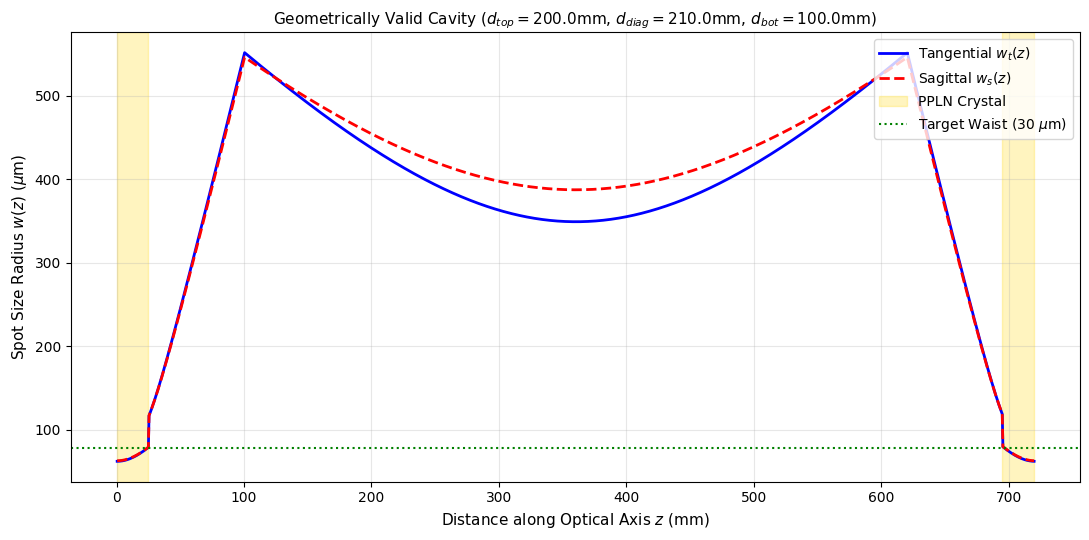

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

wavelength = 1800e-9  # meters
wavelength_mm = wavelength * 1e3  # mm

L_crystal = 50.0  # mm
n_ppln = 2.1582

R = 150.0  # Radius of curvature (mm)
theta_deg = 10.0
theta = np.radians(theta_deg)

# Astigmatic Focal Lengths
f_t = (R * np.cos(theta)) / 2.0  # Tangential plane
f_s = (R / np.cos(theta)) / 2.0  # Sagittal plane

# Target Beam Waist Radius in PPLN
w0_target_um = 78.48  # um

def M_space(d):
    return np.array([[1.0, d], [0.0, 1.0]])

def M_dielectric(L, n):
    return np.array([[1.0, L / n], [0.0, 1.0]])

def M_mirror(f):
    return np.array([[1.0, 0.0], [-1.0 / f, 1.0]])

def get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff):
    d_air_top_half = (d_top - L_crystal) / 2.0
    if d_air_top_half <= 0:
        return None

    M_half_top_fwd = M_space(d_air_top_half) @ M_dielectric(L_crystal / 2.0, n_ppln)
    M_half_top_bwd = M_dielectric(L_crystal / 2.0, n_ppln) @ M_space(d_air_top_half)

    M_rt = (
        M_half_top_bwd
        @ M_mirror(f_eff)
        @ M_space(d_diag)
        @ M_space(d_bot)
        @ M_space(d_diag)
        @ M_mirror(f_eff)
        @ M_half_top_fwd
    )
    return M_rt

def get_waist_um(M):
    if M is None:
        return None
    a, b, c, d = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
    m1 = (a + d) / 2.0
    if abs(m1) >= 1.0 or abs(b) < 1e-9:
        return None

    inv_q_imag = np.sqrt(1.0 - m1**2) / np.abs(b)
    w0_mm = np.sqrt(wavelength_mm / (np.pi * n_ppln * inv_q_imag))
    return w0_mm * 1e3


def objective_function(x):
    d_top, d_diag, d_bot = x
    if d_top <= L_crystal + 10.0:
        return 1e6
    min_diag_required = max(d_top, (d_top + d_bot) / 2.0) + 10.0
    if d_diag < min_diag_required:
        return 1e6

    M_t = get_roundtrip_matrix(d_top, d_diag, d_bot, f_t)
    M_s = get_roundtrip_matrix(d_top, d_diag, d_bot, f_s)

    w_t = get_waist_um(M_t)
    w_s = get_waist_um(M_s)

    if w_t is None or w_s is None:
        return 1e6

    return (w_t - w0_target_um) ** 2 + (w_s - w0_target_um) ** 2

class ParticleSwarmOptimizer:
    def __init__(self, obj_func, bounds, num_particles=80, max_iter=200):
        self.obj_func = obj_func
        self.bounds = np.array(bounds)
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.dim = len(bounds)

        self.X = np.random.uniform(self.bounds[:, 0], self.bounds[:, 1], (num_particles, self.dim))
        self.V = np.random.uniform(-5, 5, (num_particles, self.dim))
        self.pbest_X = self.X.copy()
        self.pbest_cost = np.array([obj_func(x) for x in self.X])

        gbest_idx = np.argmin(self.pbest_cost)
        self.gbest_X = self.pbest_X[gbest_idx].copy()
        self.gbest_cost = self.pbest_cost[gbest_idx]

    def optimize(self, w=0.7, c1=1.5, c2=1.5):
        for _ in range(self.max_iter):
            for i in range(self.num_particles):
                r1, r2 = np.random.rand(2)
                self.V[i] = (
                    w * self.V[i]
                    + c1 * r1 * (self.pbest_X[i] - self.X[i])
                    + c2 * r2 * (self.gbest_X - self.X[i])
                )
                self.X[i] += self.V[i]
                self.X[i] = np.clip(self.X[i], self.bounds[:, 0], self.bounds[:, 1])

                cost = self.obj_func(self.X[i])
                if cost < self.pbest_cost[i]:
                    self.pbest_cost[i] = cost
                    self.pbest_X[i] = self.X[i].copy()
                    if cost < self.gbest_cost:
                        self.gbest_cost = cost
                        self.gbest_X = self.X[i].copy()
        return self.gbest_X, self.gbest_cost


bounds = [(100.0, 200.0), (200.0, 500.0), (100.0, 300.0)]

np.random.seed(42)
pso = ParticleSwarmOptimizer(objective_function, bounds, num_particles=80, max_iter=200)
opt_lengths, opt_cost = pso.optimize()

d_top_opt, d_diag_opt, d_bot_opt = opt_lengths
w_t_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_t))
w_s_opt = get_waist_um(get_roundtrip_matrix(d_top_opt, d_diag_opt, d_bot_opt, f_s))


h_vertical = np.sqrt(max(0, d_diag_opt**2 - ((d_top_opt + d_bot_opt) / 2.0)**2))

print(f"--- PSO Optimization Results (Geometrically Valid) ---")
print(f"Optimal d_top  : {d_top_opt:.2f} mm")
print(f"Optimal d_diag : {d_diag_opt:.2f} mm  (d_diag > d_top: {d_diag_opt > d_top_opt})")
print(f"Optimal d_bot  : {d_bot_opt:.2f} mm")
print(f"Vertical separation (h): {h_vertical:.2f} mm")
print(f"Achieved Tangential Waist (w_t) : {w_t_opt:.2f} um")
print(f"Achieved Sagittal Waist   (w_s) : {w_s_opt:.2f} um")


def trace_spot_size(d_top, d_diag, d_bot, f_eff):
    M_rt = get_roundtrip_matrix(d_top, d_diag, d_bot, f_eff)
    w0_um = get_waist_um(M_rt)
    if w0_um is None:
        return None, None

    z_R = (np.pi * n_ppln * (w0_um * 1e-3)**2) / wavelength_mm
    q = 1j * z_R

    z_list, w_list = [], []
    current_z, dz = 0.5, 0.5

    d_air_top_half = (d_top - L_crystal) / 2.0
    path_sequence = [
        (L_crystal / 2.0, True),
        (d_air_top_half, False),
        (0.0, False, f_eff),
        (d_diag, False),
        (d_bot, False),
        (d_diag, False),
        (0.0, False, f_eff),
        (d_air_top_half, False),
        (L_crystal / 2.0, True)
    ]

    for item in path_sequence:
        dist = item[0]
        is_in_ppln = item[1]

        if len(item) == 3:
            f_m = item[2]
            q = 1.0 / (1.0 / q - 1.0 / f_m)
        elif dist > 0:
            steps = int(np.ceil(dist / dz))
            step_d = dist / steps
            n_curr = n_ppln if is_in_ppln else 1.0

            for _ in range(steps):
                z_list.append(current_z)
                inv_q = 1.0 / q
                w_mm = np.sqrt(wavelength_mm / (np.pi * n_curr * np.abs(np.imag(inv_q))))
                w_list.append(w_mm * 1e3)
                q += step_d / n_curr
                current_z += step_d

    return np.array(z_list), np.array(w_list)

z_t, w_t = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_t)
z_s, w_s = trace_spot_size(d_top_opt, d_diag_opt, d_bot_opt, f_s)

plt.figure(figsize=(11, 5.5))
plt.plot(z_t, w_t, 'b-', label=r'Tangential $w_t(z)$', lw=2)
plt.plot(z_s, w_s, 'r--', label=r'Sagittal $w_s(z)$', lw=2)

plt.axvspan(0, L_crystal / 2.0, color='gold', alpha=0.25, label='PPLN Crystal')
plt.axvspan(z_t[-1] - L_crystal / 2.0, z_t[-1], color='gold', alpha=0.25)
plt.axhline(w0_target_um, color='green', linestyle=':', label=r'Target Waist ($30\ \mu\mathrm{m}$)')

plt.title(f'Geometrically Valid Cavity ($d_{{top}}={d_top_opt:.1f}\\mathrm{{mm}}$, $d_{{diag}}={d_diag_opt:.1f}\\mathrm{{mm}}$, $d_{{bot}}={d_bot_opt:.1f}\\mathrm{{mm}}$)', fontsize=11)
plt.xlabel(r'Distance along Optical Axis $z$ (mm)', fontsize=11)
plt.ylabel(r'Spot Size Radius $w(z)$ ($\mu$m)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()